# Offsetkeuzes vastzetten na epoch 50 — vijf epochs voortzetten

**Onderzoeksvraag:** helpt het de verdere gewichtstraining als de geleerde schaalkeuze per MX-blok vanaf epoch 51 vast blijft?

We laden het bestaande checkpoint na **epoch 50** en trainen uitsluitend de variant met vaste offsets verder, tot **epoch 55**. De vergelijking gebruikt de al gemeten epochs 51–55 uit de oorspronkelijke training met verder geleerde offsets. Er wordt geen nieuwe dynamische controlerun uitgevoerd.

De gewichten blijven leren via **E4M3 → E2M3 → E2M1**; de activaties blijven **A32** en de mastergewichten **FP32**. E2M3 behoudt de hoogste twee exponentbits van de E4M3-bron. E2M1 ontstaat vervolgens via de bestaande mantissatruncatie.

Deze notebook leest alleen opgeslagen resultaten. Ze laadt geen model of checkpoint en start geen training. Alleen `SAVE_FIGURES = True` schrijft figuren, in een nieuwe analysemap.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_freeze_offsets_e50_pilot5\\20261025_174221_578057_freeze_run')
SAVE_FIGURES = False  # True: bewaar figuren in een nieuwe analysemap.


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str):
        pass
    def display(value):
        print(value)

# Gebruik de helper uit deze run; vermijd een module uit een eerder geopende notebook.
helper_path = RUN_DIR.expanduser().resolve() / 'notebook_support.py'
if not helper_path.is_file():
    raise FileNotFoundError('Stel RUN_DIR in op de resultatenmap van de freeze-offsets-proef: ' + str(helper_path.parent))
helper_name = '_mx_freeze_offsets_e50_pilot5_analysis'
spec = importlib.util.spec_from_file_location(helper_name, helper_path)
ns = importlib.util.module_from_spec(spec)
sys.modules[helper_name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(ns.diagnostics_table(run))


**Voortzetting voltooid: vijf nieuwe epochs (51–55), rapportstatus PASS.**

Geldige nieuwe meetepochs: [51, 52, 53, 54, 55]; laatste: 55. Historische referentie: gecontroleerd. Vaste offsetkeuzes: bevestigd in de opgeslagen controles.

Het primaire vergelijkingspunt is epoch 55. Het aanvullende beste checkpoint wordt per variant door E4M3 gekozen, uitsluitend binnen 51–55. Alle drie de precisies gebruiken binnen zo’n groep dezelfde epoch.

,Onderdeel,Afspraak
0,Start,Het bestaande checkpoint na epoch 50; geen nie...
1,Nieuwe training,Alleen de variant met vastgezette offsets: epo...
2,Historische vergelijking,Bestaande dynamische epochs 51–55 uit de afger...
3,Offsetkeuze per blok,Na epoch 50 behouden: 1654×32; 2426×64
4,E4M3-bronschaal,Blijft opnieuw bepaald uit de actuele gewichten
5,Gewichten / activaties,FP32-master; E4M3 → E2M3 → E2M1; alle activati...
6,Gewichts-LR51–55,"0,0001; schema en optimizerstatus geërfd van h..."
7,Schaal-LR51–55,0; opgeslagen proxywaarden en harde keuzes bli...
8,Primair eindpunt,Alle drie testaccuracies op epoch 55
9,Aanvullende selectie,Eerste hoogste E4M3-testaccuracy binnen 51–55;...


,Niveau,Melding
0,INTERPRETATIE,De dynamische variant is de bestaande training...


## Wat wordt vastgezet?

Voor ieder blok blijft de lagere shared exponent:

$$E_{\mathrm{laag},b}(t) = E_{\mathrm{E4M3},b}(t) + k_b.$$

De extra offset $k_b$ blijft gelijk aan de keuze na epoch 50: **5 voor ×32** of **6 voor ×64**. De E4M3-broncode en bronschaal worden nog steeds uit de actuele gewichten bepaald. Daardoor kan de uiteindelijke shared exponent nog veranderen terwijl de extra offset vast blijft.

Technisch krijgen de schaalproxy's een learning rate van **nul**. De bestaande gradientberekening en Adam-momentupdates blijven actief om de oorspronkelijke training zo weinig mogelijk te wijzigen. Na elke optimizerstap wordt gecontroleerd dat alle proxywaarden en harde keuzes exact dezelfde zijn gebleven. Deze proef meet daardoor geen geoptimaliseerde trainingsbesparing door het verwijderen van schaalgradients.

De eerste figuur toont het gemeenschappelijke checkpoint na epoch 50 en de twee trajecten daarna. De historische dynamische variant staat gestippeld; de nieuwe vaste-offsetvariant staat doorgetrokken.


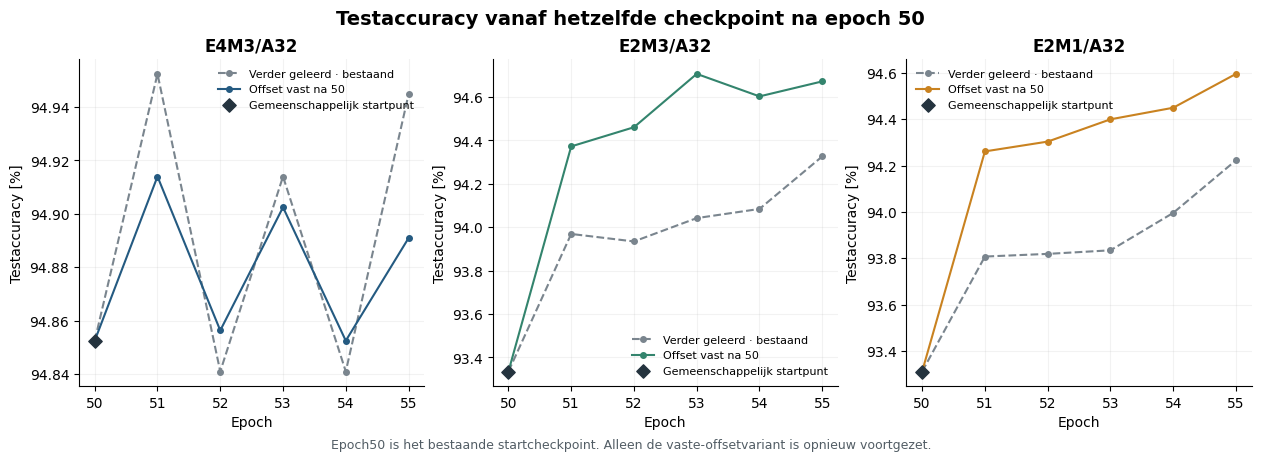

In [3]:
figures['accuracy_curves'] = ns.plot_accuracy_curves(run)
display(figures['accuracy_curves'])
plt.close(figures['accuracy_curves'])


## Primair vergelijkingspunt: epoch 55

We vergelijken alle drie de precisies op **dezelfde epoch 55**. Het verschil hieronder is **vaste offset minus verder geleerde offset**, uitgedrukt in procentpunt. Deze groep wordt pas getoond als epoch 55 daadwerkelijk is gemeten.


,Variant,Selectie,Epoch,Precisie,Testaccuracy [%],Correct,Testbeelden
0,Offset verder geleerd (bestaand),Primair: epoch 55,55,E4M3/A32,94.944683,24716,26032
1,Offset verder geleerd (bestaand),Primair: epoch 55,55,E2M3/A32,94.326214,24555,26032
2,Offset verder geleerd (bestaand),Primair: epoch 55,55,E2M1/A32,94.222495,24528,26032
3,Offset vast na epoch 50,Primair: epoch 55,55,E4M3/A32,94.890903,24702,26032
4,Offset vast na epoch 50,Primair: epoch 55,55,E2M3/A32,94.671942,24645,26032
5,Offset vast na epoch 50,Primair: epoch 55,55,E2M1/A32,94.595114,24625,26032


,Epoch,Precisie,Vaste offset [%],Verder geleerd [%],Verschil [procentpunt],Verschil correct voorspeld
12,55,E2M1,94.595114,94.222495,0.372618,97
13,55,E2M3,94.671942,94.326214,0.345728,90
14,55,E4M3,94.890903,94.944683,-0.053780,-14


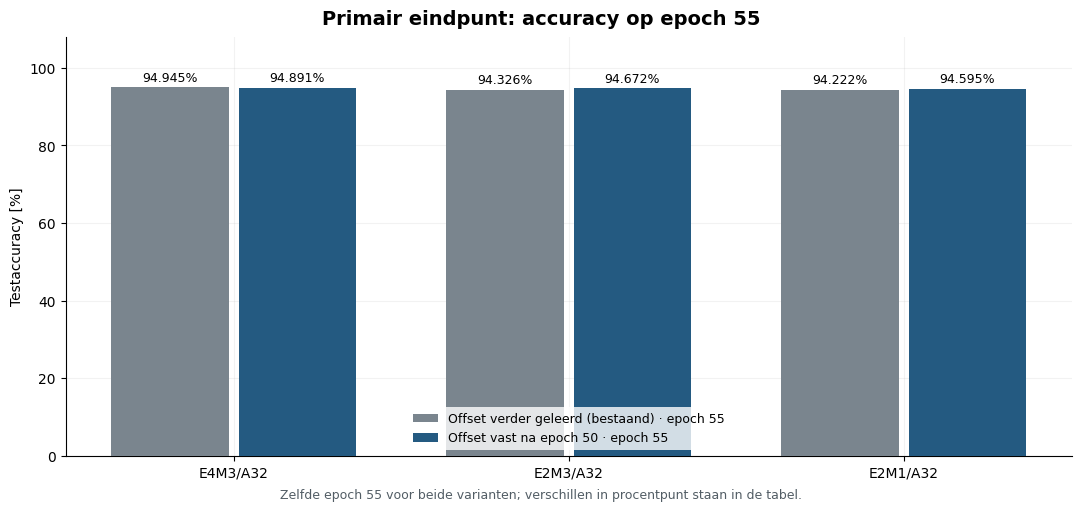

In [4]:
display(ns.checkpoint_table(run, 'endpoint').drop(columns=['weight_bits']).round({'Testaccuracy [%]': 6}))
delta = ns.delta_table(run)
if not delta.empty:
    display(delta.loc[delta.Epoch.eq(55)].drop(columns=['weight_bits']).round(6))
figures['accuracy_epoch55'] = ns.plot_checkpoint_accuracy(run, 'endpoint')
display(figures['accuracy_epoch55'])
plt.close(figures['accuracy_epoch55'])


## Aanvullend: beste checkpoint gekozen door E4M3

Per variant kiezen we het **eerste maximum van de E4M3-testaccuracy binnen epochs 51–55**. Vervolgens tonen we E4M3, E2M3 en E2M1 op precies diezelfde epoch. De varianten mogen hierbij elk een andere geselecteerde epoch hebben. Het globale beste checkpoint uit de oorspronkelijke 100-epochtraining wordt voor deze vergelijking niet gebruikt.

Bij een onderbroken voortzetting wordt alleen over het gemeenschappelijk gemeten deel van 51–55 geselecteerd en blijft de uitkomst voorlopig. Zoals in het bestaande protocol gebeurt de selectie op de officiële testset; de geselecteerde score is dus geen onafhankelijke validatiescore.


,Variant,Selectie,Epoch,Precisie,Testaccuracy [%],Correct,Testbeelden
0,Offset verder geleerd (bestaand),E4M3-best binnen 51–55,51,E4M3/A32,94.952366,24718,26032
1,Offset verder geleerd (bestaand),E4M3-best binnen 51–55,51,E2M3/A32,93.968961,24462,26032
2,Offset verder geleerd (bestaand),E4M3-best binnen 51–55,51,E2M1/A32,93.807621,24420,26032
3,Offset vast na epoch 50,E4M3-best binnen 51–55,51,E4M3/A32,94.913952,24708,26032
4,Offset vast na epoch 50,E4M3-best binnen 51–55,51,E2M3/A32,94.372311,24567,26032
5,Offset vast na epoch 50,E4M3-best binnen 51–55,51,E2M1/A32,94.260910,24538,26032


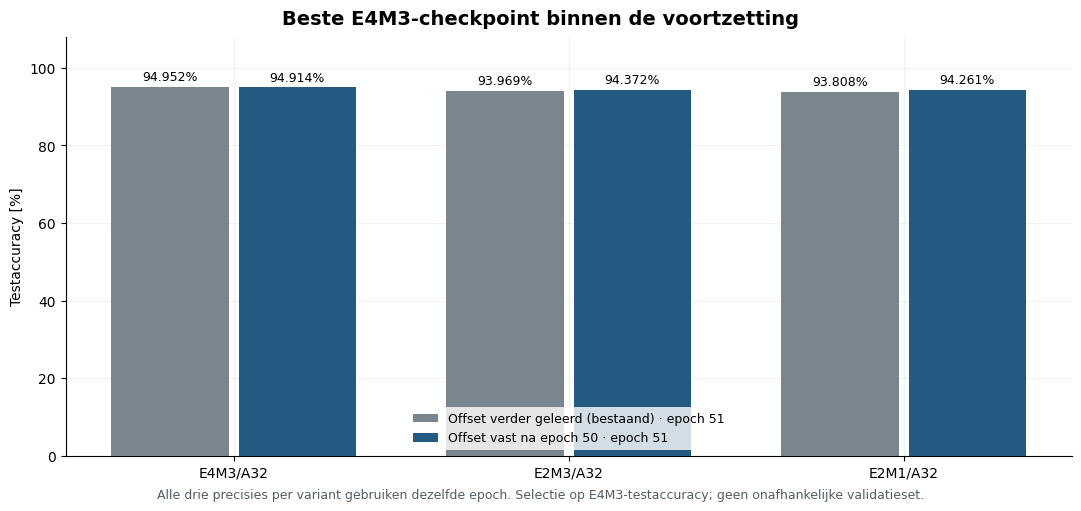

In [5]:
display(ns.checkpoint_table(run, 'best').drop(columns=['weight_bits']).round({'Testaccuracy [%]': 6}))
figures['accuracy_best_E4_within_window'] = ns.plot_checkpoint_accuracy(run, 'best')
display(figures['accuracy_best_E4_within_window'])
plt.close(figures['accuracy_best_E4_within_window'])


## Accuracyverschillen gedurende de voortzetting

Deze figuur gebruikt voor elke epoch en precisie de bijbehorende historische meting. De vijf epochs zijn opeenvolgende toestanden van één training, geen vijf onafhankelijke herhalingen. Positieve verschillen betekenen een hogere accuracy met vaste offsets; negatieve verschillen betekenen een lagere accuracy.


,Epoch,Precisie,Vaste offset [%],Verder geleerd [%],Verschil [procentpunt],Verschil correct voorspeld
0,51,E2M1,94.260910,93.807621,0.453288,118
1,51,E2M3,94.372311,93.968961,0.403350,105
2,51,E4M3,94.913952,94.952366,-0.038414,-10
3,52,E2M1,94.303165,93.819146,0.484020,126
4,52,E2M3,94.460664,93.934388,0.526275,137
5,52,E4M3,94.856331,94.840965,0.015366,4
6,53,E2M1,94.399201,93.834511,0.564690,147
7,53,E2M3,94.706515,94.041948,0.664567,173
8,53,E4M3,94.902428,94.913952,-0.011524,-3
9,54,E2M1,94.449140,93.995851,0.453288,118


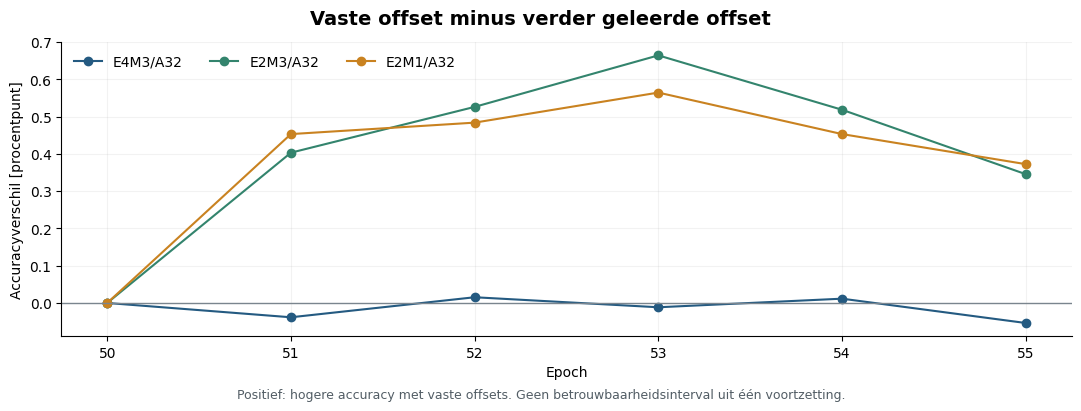

In [6]:
if not delta.empty:
    display(delta.drop(columns=['weight_bits']).round(6))
figures['accuracy_delta'] = ns.plot_accuracy_delta(run)
display(figures['accuracy_delta'])
plt.close(figures['accuracy_delta'])


## Controle: blijven de offsets werkelijk vast?

We controleren zowel de opgeslagen FP32-proxywaarden als de harde keuzes. De nieuwe voortzetting moet **nul gewijzigde proxy's en nul offsetwissels** tonen. Het aandeel ×32 blijft gelijk aan het startcheckpoint. Een constant totaal aandeel alleen zou onvoldoende zijn: verschillende blokken kunnen in tegengestelde richting wisselen en elkaar in dat totaal compenseren.

De teller 'offsetwissels tijdens epoch' telt gebeurtenissen. Een blok kan in de historische dynamische variant meerdere keren in één epoch wisselen.


,Epoch,Blokken,×32,×64,Gewijzigde proxy’s,Offsetwissels tijdens epoch,Blokken met offsetwissel,Aandeel ×32 [%]
0,51,4080,1654,2426,0,0,0,40.539216
1,52,4080,1654,2426,0,0,0,40.539216
2,53,4080,1654,2426,0,0,0,40.539216
3,54,4080,1654,2426,0,0,0,40.539216
4,55,4080,1654,2426,0,0,0,40.539216


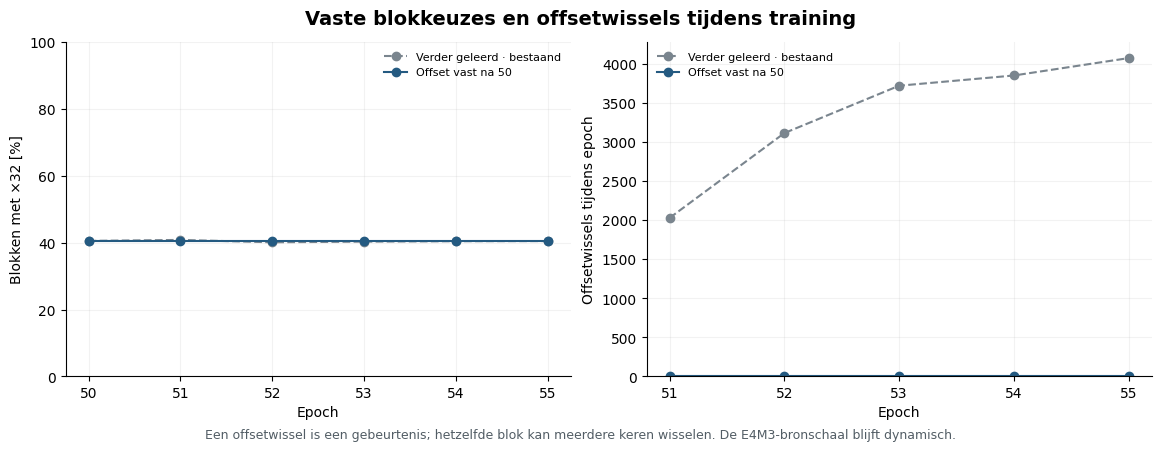

In [7]:
display(ns.freeze_table(run).round(6))
figures['scale_choices_and_switches'] = ns.plot_scale_choices(run)
display(figures['scale_choices_and_switches'])
plt.close(figures['scale_choices_and_switches'])


## Trainingsobjectief

E4M3 gebruikt harde cross-entropy. E2M3 en E2M1 gebruiken ieder zachte cross-entropy met de vorige precisie als losgekoppelde leraar. Vergelijk de twee varianten per precisie; de drie trainingsobjectieven zijn niet onderling gelijk aan harde test-cross-entropy.


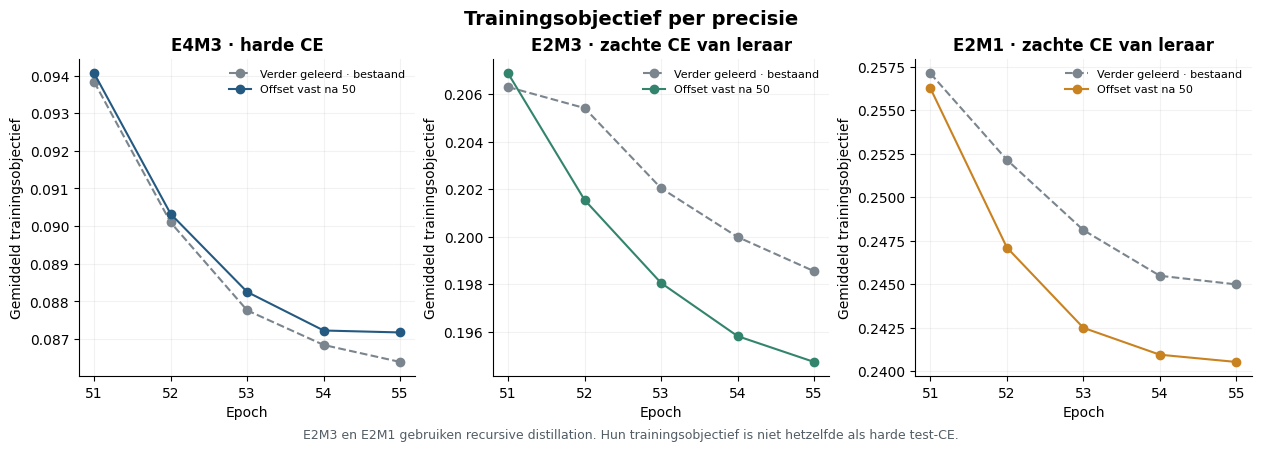

In [8]:
figures['training_objectives'] = ns.plot_objectives(run)
display(figures['training_objectives'])
plt.close(figures['training_objectives'])


## Gemeten duur en interpretatie

De epochtijden omvatten training, evaluatie, controles en checkpointschrijven. De nieuwe uitvoering start vanaf een checkpoint en kan andere opstart- of uitvoeringskosten hebben. De waarden hieronder zijn daarom beschrijvende metingen van deze runs. Dit is een FP32-emulatie van de MX-gewichten; ze meet geen native MX-versnelling of energieverbruik.


,Variant,Epoch,Gemeten epochtijd [s]
0,Offset verder geleerd (bestaand),51,59.645
1,Offset verder geleerd (bestaand),52,59.678
2,Offset verder geleerd (bestaand),53,59.371
3,Offset verder geleerd (bestaand),54,59.353
4,Offset verder geleerd (bestaand),55,60.371
5,Offset vast na epoch 50,51,65.777
6,Offset vast na epoch 50,52,63.808
7,Offset vast na epoch 50,53,60.456
8,Offset vast na epoch 50,54,59.209
9,Offset vast na epoch 50,55,59.225


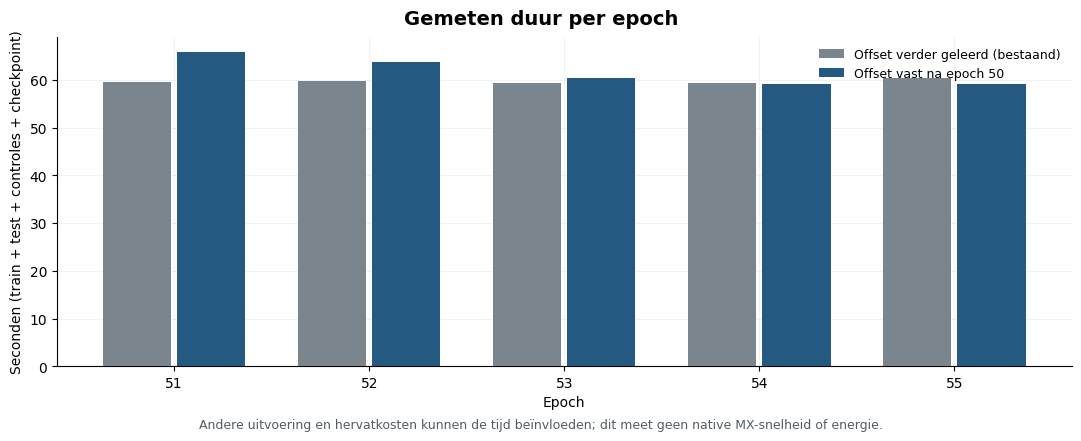

In [9]:
display(ns.timing_table(run).round(3))
figures['epoch_timing'] = ns.plot_timing(run)
display(figures['epoch_timing'])
plt.close(figures['epoch_timing'])


## Hoe beoordelen we de proef?

- Begin met de drie accuracies op **epoch 55** en hun verschillen met de bestaande dynamische training.
- Bekijk vervolgens of een verschil gedurende meerdere gemeten epochs in dezelfde richting gaat en of de controle daadwerkelijk nul offsetwissels bevestigt.
- Gebruik de E4M3-selectie als aanvullend overzicht: alle drie de modi blijven gekoppeld aan één checkpoint per variant.
- De bestaande CUDA-instellingen garanderen geen bitexacte herhaling. Eén voortzetting geeft geen schatting van de spreiding tussen runs; een klein verschil verdient voorzichtigheid.
- Een gunstige uitkomst ondersteunt verder onderzoek naar het vastzetten van de offsetkeuzes. Deze proef bepaalt op zichzelf geen optimaal moment om daarmee te beginnen.

De referentiebestanden en hun herkomst zijn meegeleverd onder `parent_reference`. De analyse verifieert hun hashes en vergelijkt de opgeslagen train-/testvolgorde met die van de oorspronkelijke epochs 51–55.


In [10]:
if SAVE_FIGURES:
    destination = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', destination)
else:
    print('Alleen gelezen en weergegeven; bestaande resultaten zijn ongewijzigd.')


Alleen gelezen en weergegeven; bestaande resultaten zijn ongewijzigd.
